# Phishin Model Training 

## Dtaset 

In [6]:
# IMPORTATIONS 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import metrics
from sklearn.metrics import confusion_matrix , accuracy_score , precision_score , recall_score , f1_score , classification_report



### Part1 : Data treatment 

In [7]:
# Loading data 

data = pd.read_csv('../../data/phishing.csv')
print(data.head())

   Index  UsingIP  LongURL  ShortURL  Symbol@  Redirecting//  PrefixSuffix-  \
0      0        1        1         1        1              1             -1   
1      1        1        0         1        1              1             -1   
2      2        1        0         1        1              1             -1   
3      3        1        0        -1        1              1             -1   
4      4       -1        0        -1        1             -1             -1   

   SubDomains  HTTPS  DomainRegLen  ...  UsingPopupWindow  IframeRedirection  \
0           0      1            -1  ...                 1                  1   
1          -1     -1            -1  ...                 1                  1   
2          -1     -1             1  ...                 1                  1   
3           1      1            -1  ...                -1                  1   
4           1      1            -1  ...                 1                  1   

   AgeofDomain  DNSRecording  WebsiteTraffic

In [8]:
# INFORMATION ABOUT THE DATASET

print(data.describe())

              Index       UsingIP       LongURL      ShortURL       Symbol@  \
count  11054.000000  11054.000000  11054.000000  11054.000000  11054.000000   
mean    5526.500000      0.313914     -0.633345      0.738737      0.700561   
std     3191.159272      0.949495      0.765973      0.674024      0.713625   
min        0.000000     -1.000000     -1.000000     -1.000000     -1.000000   
25%     2763.250000     -1.000000     -1.000000      1.000000      1.000000   
50%     5526.500000      1.000000     -1.000000      1.000000      1.000000   
75%     8289.750000      1.000000     -1.000000      1.000000      1.000000   
max    11053.000000      1.000000      1.000000      1.000000      1.000000   

       Redirecting//  PrefixSuffix-    SubDomains         HTTPS  DomainRegLen  \
count   11054.000000   11054.000000  11054.000000  11054.000000  11054.000000   
mean        0.741632      -0.734938      0.064049      0.251040     -0.336711   
std         0.670837       0.678165      0.81

In [9]:
# DATA COLUMNS

print(data.columns)

Index(['Index', 'UsingIP', 'LongURL', 'ShortURL', 'Symbol@', 'Redirecting//',
       'PrefixSuffix-', 'SubDomains', 'HTTPS', 'DomainRegLen', 'Favicon',
       'NonStdPort', 'HTTPSDomainURL', 'RequestURL', 'AnchorURL',
       'LinksInScriptTags', 'ServerFormHandler', 'InfoEmail', 'AbnormalURL',
       'WebsiteForwarding', 'StatusBarCust', 'DisableRightClick',
       'UsingPopupWindow', 'IframeRedirection', 'AgeofDomain', 'DNSRecording',
       'WebsiteTraffic', 'PageRank', 'GoogleIndex', 'LinksPointingToPage',
       'StatsReport', 'class'],
      dtype='str')


In [10]:
#CHECKING FOR NULL VALUES

print(data.isnull().sum())

Index                  0
UsingIP                0
LongURL                0
ShortURL               0
Symbol@                0
Redirecting//          0
PrefixSuffix-          0
SubDomains             0
HTTPS                  0
DomainRegLen           0
Favicon                0
NonStdPort             0
HTTPSDomainURL         0
RequestURL             0
AnchorURL              0
LinksInScriptTags      0
ServerFormHandler      0
InfoEmail              0
AbnormalURL            0
WebsiteForwarding      0
StatusBarCust          0
DisableRightClick      0
UsingPopupWindow       0
IframeRedirection      0
AgeofDomain            0
DNSRecording           0
WebsiteTraffic         0
PageRank               0
GoogleIndex            0
LinksPointingToPage    0
StatsReport            0
class                  0
dtype: int64


In [11]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 11054 entries, 0 to 11053
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Index                11054 non-null  int64
 1   UsingIP              11054 non-null  int64
 2   LongURL              11054 non-null  int64
 3   ShortURL             11054 non-null  int64
 4   Symbol@              11054 non-null  int64
 5   Redirecting//        11054 non-null  int64
 6   PrefixSuffix-        11054 non-null  int64
 7   SubDomains           11054 non-null  int64
 8   HTTPS                11054 non-null  int64
 9   DomainRegLen         11054 non-null  int64
 10  Favicon              11054 non-null  int64
 11  NonStdPort           11054 non-null  int64
 12  HTTPSDomainURL       11054 non-null  int64
 13  RequestURL           11054 non-null  int64
 14  AnchorURL            11054 non-null  int64
 15  LinksInScriptTags    11054 non-null  int64
 16  ServerFormHandler    11054 non-nu

In [12]:
# Dropping index column 
data = data.drop(columns=["Index"])
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 11054 entries, 0 to 11053
Data columns (total 31 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   UsingIP              11054 non-null  int64
 1   LongURL              11054 non-null  int64
 2   ShortURL             11054 non-null  int64
 3   Symbol@              11054 non-null  int64
 4   Redirecting//        11054 non-null  int64
 5   PrefixSuffix-        11054 non-null  int64
 6   SubDomains           11054 non-null  int64
 7   HTTPS                11054 non-null  int64
 8   DomainRegLen         11054 non-null  int64
 9   Favicon              11054 non-null  int64
 10  NonStdPort           11054 non-null  int64
 11  HTTPSDomainURL       11054 non-null  int64
 12  RequestURL           11054 non-null  int64
 13  AnchorURL            11054 non-null  int64
 14  LinksInScriptTags    11054 non-null  int64
 15  ServerFormHandler    11054 non-null  int64
 16  InfoEmail            11054 non-nu

In [15]:
x = data.drop(columns=["class"])
y = data["class"]
y = y.map({-1: 0, 1: 1})
print(x.shape , y.shape )

(11054, 30) (11054,)


#### Phishing ratio 

In [54]:
print("Normal website Count : " , y.loc[y == 0].count())
print("\n\n")
print("Phishing website count : " , y.loc[y == 1].count())


Normal website Count :  4897



Phishing website count :  6157


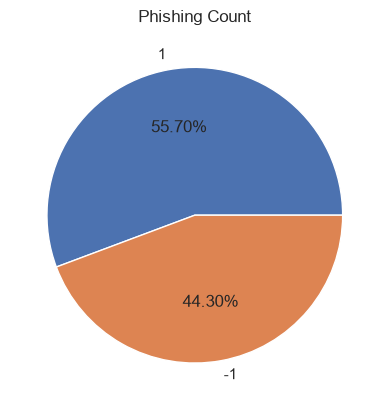

In [55]:
# Phishing count in pie chart 

data['class'].value_counts().plot(kind='pie',autopct='%1.2f%%')
plt.title("Phishing Count")
plt.show()

#### Train test Splitting 

In [56]:
# Train test splitting 

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((8843, 30), (8843,), (2211, 30), (2211,))

### Part2 : Model training 

***Algorithms to be used and compared:***

 1. K-nearest neighbors
 2. Naive Bayes
 3. Logistic regression 
 4. SVM
 5. Decision tree
 6. Xgboost 
 7. Catboost

***.Metrics display function***

In [57]:
def show_metrics(eval_results):
    for key,value in eval_results.items() :
        if key == "confusion_matrix":
            mat_conf(eval_results["confusion_matrix"])
            break
        print(key ," : " ,  value)
        print("\n\n")


#### ***Plotting functions***

***Confusion Matrix plotting function***

In [58]:
def mat_conf(matrix):
    plt.figure(figsize = (10,7))
    sns.heatmap(matrix , annot = True , fmt = "d" , xticklabels=["Normal" , "Phishing"] , yticklabels=["Normal" , "Phishing"] )
    plt.title("Matrice de confusion ")
    plt.xlabel("Predicted values")
    plt.ylabel("True values")
    plt.show()

***.Comparision plotting function***

In [59]:

# PLot the different metrics returned by testing different values of an algorithm's hyperparameter 

def plot_cmp( results , cmp_subject , title , metrics=None , titlex=None , titley=None  ):
    
    df = pd.DataFrame(results).T

    # 2. Cast columns to proper numeric types (fixes the object dtype issue)
    metrics = ['accuracy', 'precision', 'recall', 'f1score'] if metrics == None else metrics
    for col in metrics:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    df['neighbors'] = pd.to_numeric(df[cmp_subject], errors='coerce', downcast='integer')

    # 3. Reshape into long format
    df_long = df.melt(id_vars=[cmp_subject], value_vars=metrics, var_name='Metric', value_name='Score')

    # 4. Plot
    plt.figure(figsize=(10, 6))
    sns.set_theme(style="whitegrid")

    sns.lineplot(
        data=df_long, 
        x= cmp_subject, 
        y='Score', 
        hue='Metric',
        style='Metric', 
        marker='o', 
        linewidth=2.5,
        alpha=0.7
    )

    plt.title(title, fontsize=14)
    plt.xlabel(titlex if titlex else cmp_subject, fontsize=12)
    plt.ylabel(titley if titley else 'Score', fontsize=12)
    plt.xticks(df['neighbors'].unique())
    plt.legend(title='Metric')

    plt.show()


In [60]:
# Comparing training and testing accuracies , usefull for detecting 
# overfitting : high training accuracy , but significantly lower test accurarcy
# Underfitting : Low accuracy on both training and testing sets 

def cmp_train_test(train_results , test_results , subject , subject_values):
    # COMPARING MODEL ACCURACY ON TRAINING VS TESTING SETS 

    training_accuracies = [metrics["accuracy"] for metrics in train_results.values()]

    test_accuracies = [metrics["accuracy"] for metrics in test_results.values()]


    #plotting the training & testing accuracy for n_estimators from 1 to 20
    plt.plot(subject_values, training_accuracies, label="training accuracy")
    plt.plot(subject_values, test_accuracies, label="test accuracy")
    plt.xticks(subject_values)
    plt.ylabel("Accuracy")  
    plt.xlabel(subject)
    plt.legend();
        

#### **1. K-nearest neighbors**

In [61]:
# IMPORTATIN
from sklearn.neighbors import KNeighborsClassifier 


In [62]:
# INITIALISATION / TRAINING

def construct_knn(neighbors):
    knn = KNeighborsClassifier(n_neighbors=neighbors)
    knn.fit(x_train,y_train)
    return knn


In [63]:
# PREDICTION 
def knn_predict(knn , x_predict):
    y_pred = knn.predict(x_predict)
    return {"neighbors":knn.n_neighbors,"prediction":y_pred}

In [64]:
# Testing different values of n_neighbors
knns_train = {}
knns_test = {}
neighbors= [3,5,7,11,15]

for n in neighbors:
    knns_train[n]= knn_predict(construct_knn(n),x_train)
    knns_test[n] = knn_predict(construct_knn(n) , x_test)



In [65]:
print(knns_train)
print(knns_test)

{3: {'neighbors': 3, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}, 5: {'neighbors': 5, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}, 7: {'neighbors': 7, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}, 11: {'neighbors': 11, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}, 15: {'neighbors': 15, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}}
{3: {'neighbors': 3, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}, 5: {'neighbors': 5, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}, 7: {'neighbors': 7, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}, 11: {'neighbors': 11, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}, 15: {'neighbors': 15, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}}


In [66]:
# EVALUATION 
def knns_eval(knns , real_y):
    results = {}
    i=0
    for key, item in knns.items():
            # Retrieve y_pred and neighbor count based on dictionary structure
           
            if isinstance(item, dict):
                y_pred = item["prediction"]
                neighbors = item["neighbors"]
            
            # Compute evaluation metrics comparing y_pred with y_val
            
            results[i] = {
                "neighbors": neighbors,
                "accuracy": accuracy_score(real_y, y_pred),
                "precision": precision_score(real_y, y_pred, average='weighted'),
                "recall": recall_score(real_y, y_pred, average='weighted'),
                "f1score": f1_score(real_y, y_pred, average='weighted'),
                "confusion_matrix": confusion_matrix(real_y, y_pred)
            }
            i=i+1
            
    return results

def knn_eval(knn , real_y):
    y_pred = knn["prediction"]
    neighbors = knn["neighbors"]
    # Compute evaluation metrics comparing y_pred with y_val
    results = {
            "neighbors": neighbors,
            "accuracy": accuracy_score(real_y, y_pred),
            "precision": precision_score(real_y, y_pred, average='weighted'),
            "recall": recall_score(real_y, y_pred, average='weighted'),
            "f1score": f1_score(real_y, y_pred, average='weighted'),
            "confusion_matrix": confusion_matrix(real_y, y_pred)
    }
            
    return results 

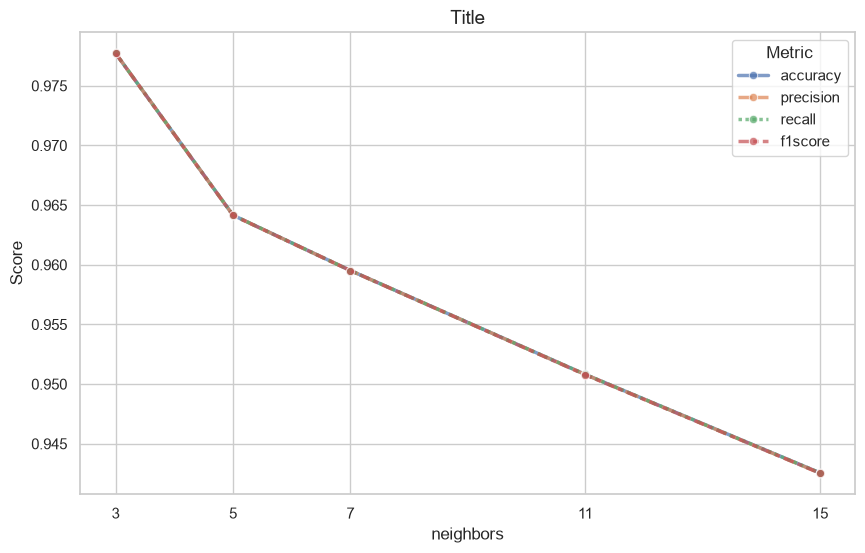

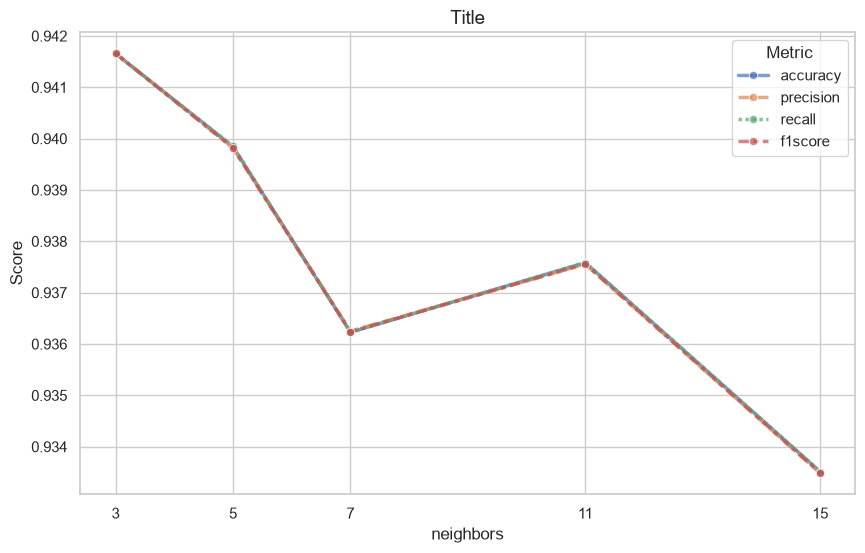

In [67]:
# METRICS 

knns_train_results = knns_eval(knns_train , y_train)
knns_test_results = knns_eval(knns_test , y_test)

plot_cmp(knns_train_results , "neighbors" , "Title")
plot_cmp(knns_test_results , "neighbors" , "Title")

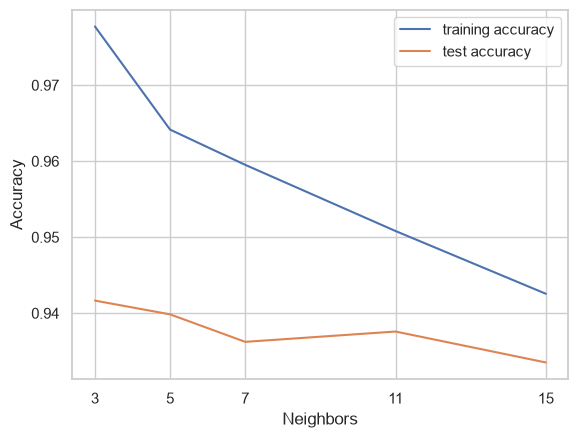

In [68]:
cmp_train_test(knns_train_results , knns_test_results , "Neighbors" , neighbors)

***Best n-neighbors configuration = 3***

neighbors  :  3



accuracy  :  0.9416553595658074



precision  :  0.9416619929159197



recall  :  0.9416553595658074



f1score  :  0.9416584813102012





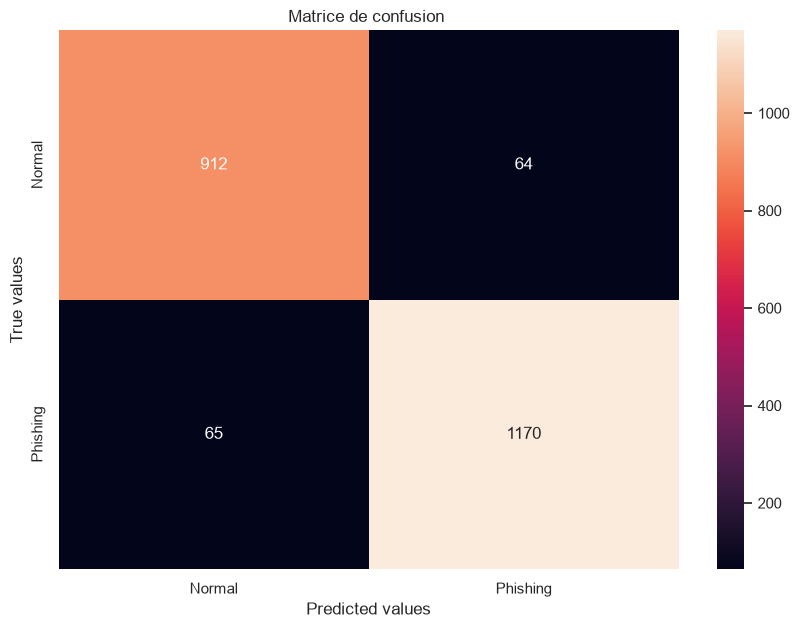

In [69]:
# Final model 
final_knn = construct_knn(3)

knn_eval_results = knn_eval(knn_predict(final_knn , x_test ) , y_test)
show_metrics(knn_eval_results)


#### **2. Naive Bayes**

In [70]:
# IMPORTATION 
from sklearn.naive_bayes import GaussianNB

In [71]:
# INITIALISATION / TRAINING

def construct_nb():
    gnb = GaussianNB(var_smoothing=1e-8)
    gnb.fit(x_train , y_train)
    return gnb

gnb = construct_nb()


In [72]:
# PREDICTION 
nb_y_test_pred = gnb.predict(x_test)
nb_y_train_pred = gnb.predict(x_train)

In [73]:
# EVALUATION 
def eval_nb(y_pred , real_y):
     # Compute evaluation metrics comparing y_pred with real_y
        results = {
                "accuracy": accuracy_score(real_y, y_pred),
                "precision": precision_score(real_y, y_pred, average='weighted'),
                "recall": recall_score(real_y, y_pred, average='weighted'),
                "f1score": f1_score(real_y, y_pred, average='weighted'),
                "confusion_matrix": confusion_matrix(real_y, y_pred)
            }
            
        return results 




Evaluating Prediction on Training set 

 
accuracy  :  0.6310075766142712



precision  :  0.7956692270542738



recall  :  0.6310075766142712



f1score  :  0.5942824901795027





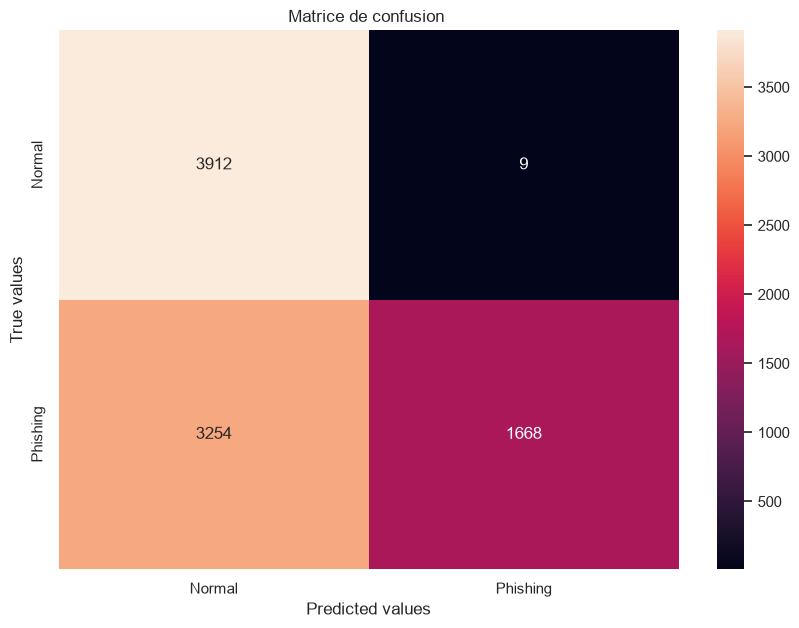



Evaluating Prediction on Training set 

 
accuracy  :  0.6282225237449118



precision  :  0.7942537394390599



recall  :  0.6282225237449118



f1score  :  0.5913139861377856





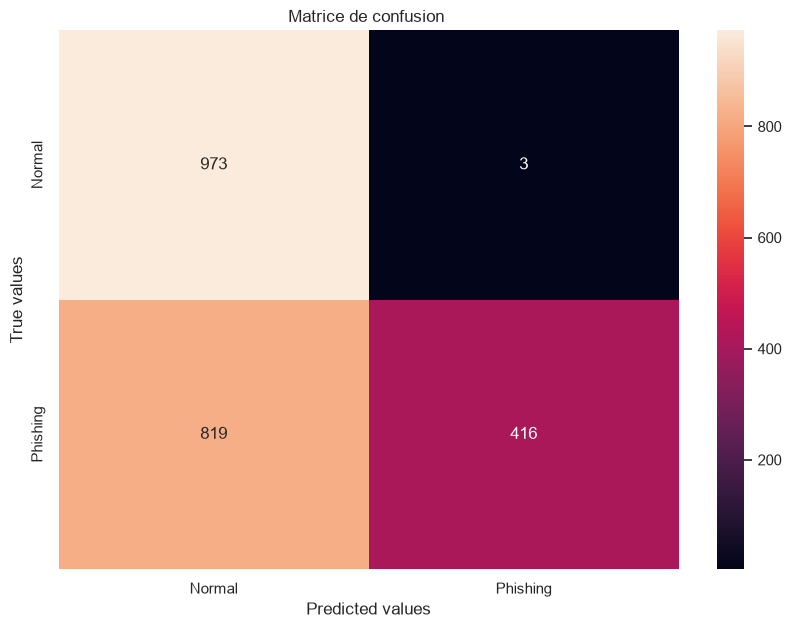

In [74]:
# METRICS 
nb_eval_train_results = eval_nb(nb_y_train_pred,y_train)
nb_eval_results = eval_nb(nb_y_test_pred , y_test)

print("Evaluating Prediction on Training set \n\n ")
show_metrics(nb_eval_train_results)

print("\n\nEvaluating Prediction on Training set \n\n ")

show_metrics(nb_eval_results)

#### **3. Logistic regression**

In [75]:
# IMPORTATION
from sklearn.linear_model import LogisticRegression

In [76]:
# INITIALISATION / TRAINING

def construct_lrg(c_val):
    lrg = LogisticRegression(solver='lbfgs' , C=c_val , random_state=42)
    lrg.fit(x_train , y_train)
    return lrg 


In [77]:
# PREDICTION 

def lrg_predict(lrg , x_predict ):
    y_pred = lrg.predict(x_predict)
    return {"c_val":lrg.C,"prediction":y_pred}

In [78]:
# Testing different values of C 

lrgs_train = {}
lrgs_test = {}
c_vals = [0.1 , 1 , 10]

for c_val in c_vals:
    lrgs_train[c_val]=lrg_predict(construct_lrg(c_val),x_train)
    lrgs_test[c_val]=lrg_predict(construct_lrg(c_val),x_test)


print(lrgs_train)
print(lrgs_test)

{0.1: {'c_val': 0.1, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}, 1: {'c_val': 1, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}, 10: {'c_val': 10, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}}
{0.1: {'c_val': 0.1, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}, 1: {'c_val': 1, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}, 10: {'c_val': 10, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}}


In [79]:
# EVALUATION 

def lrgs_eval(lrgs , real_y):
    results = {}

    for key , item in lrgs.items():
        if isinstance(item,dict):
            y_pred = item["prediction"]
            c_val = item["c_val"]
            def eval_lrg(y_pred ,real_y):
                
                # Compute evaluation metrics comparing y_pred with real_y
                results = {
                        "c_val" : c_val,
                        "accuracy": accuracy_score(real_y, y_pred),
                        "precision": precision_score(real_y, y_pred, average='weighted'),
                        "recall": recall_score(real_y, y_pred, average='weighted'),
                        "f1score": f1_score(real_y, y_pred, average='weighted'),
                        "confusion_matrix": confusion_matrix(real_y, y_pred)
                    }
                return results 
        results[key] = eval_lrg(y_pred , real_y)
    return results 
    

def lrg_eval(y_pred ,real_y , c_val):
                
                # Compute evaluation metrics comparing y_pred with real_y
                results = {
                        "c_val" : c_val,
                        "accuracy": accuracy_score(real_y, y_pred),
                        "precision": precision_score(real_y, y_pred, average='weighted'),
                        "recall": recall_score(real_y, y_pred, average='weighted'),
                        "f1score": f1_score(real_y, y_pred, average='weighted'),
                        "confusion_matrix": confusion_matrix(real_y, y_pred)
                    }
                return results 


In [80]:
lrgs_train_eval = lrgs_eval(lrgs_train , y_train)
lrgs_test_eval = lrgs_eval(lrgs_test , y_test)

print(lrgs_train_eval)
print(lrgs_test_eval)

{0.1: {'c_val': 0.1, 'accuracy': 0.9278525387311998, 'precision': 0.9279215201253991, 'recall': 0.9278525387311998, 'f1score': 0.9277356776610951, 'confusion_matrix': array([[3546,  375],
       [ 263, 4659]])}, 1: {'c_val': 1, 'accuracy': 0.9269478683704625, 'precision': 0.9269524913294581, 'recall': 0.9269478683704625, 'f1score': 0.9268569648008823, 'confusion_matrix': array([[3554,  367],
       [ 279, 4643]])}, 10: {'c_val': 10, 'accuracy': 0.9264955331900938, 'precision': 0.9264950389716425, 'recall': 0.9264955331900938, 'f1score': 0.9264063147392472, 'confusion_matrix': array([[3553,  368],
       [ 282, 4640]])}}
{0.1: {'c_val': 0.1, 'accuracy': 0.9348710990502035, 'precision': 0.9350517488752995, 'recall': 0.9348710990502035, 'f1score': 0.9347360046462422, 'confusion_matrix': array([[ 887,   89],
       [  55, 1180]])}, 1: {'c_val': 1, 'accuracy': 0.9335142469470827, 'precision': 0.933639375574251, 'recall': 0.9335142469470827, 'f1score': 0.9333898392567606, 'confusion_matrix':

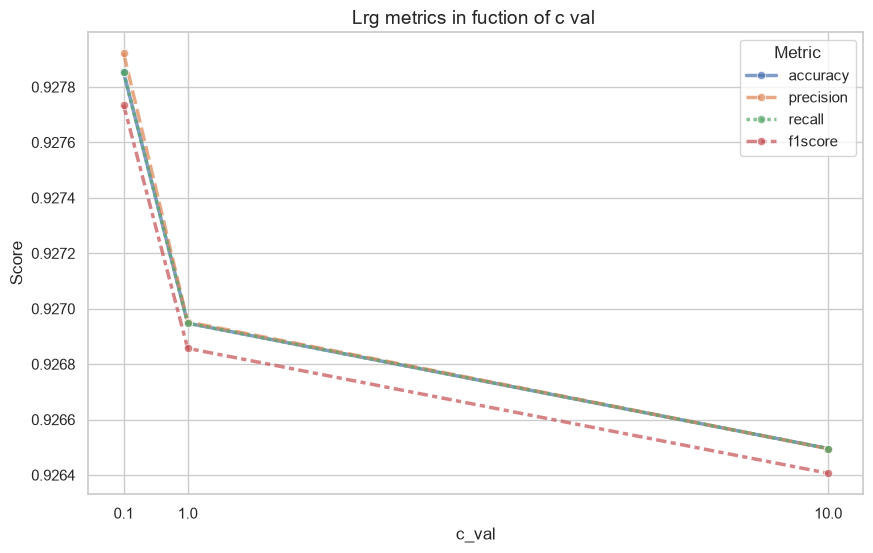

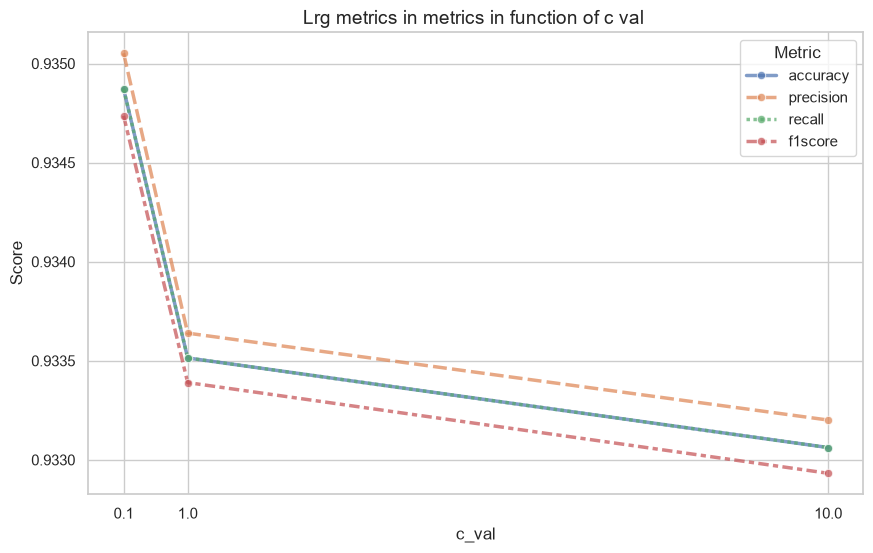

In [81]:
plot_cmp(lrgs_train_eval , "c_val" , "Lrg metrics in fuction of c val ")
plot_cmp(lrgs_test_eval , "c_val" , "Lrg metrics in metrics in function of c val ")

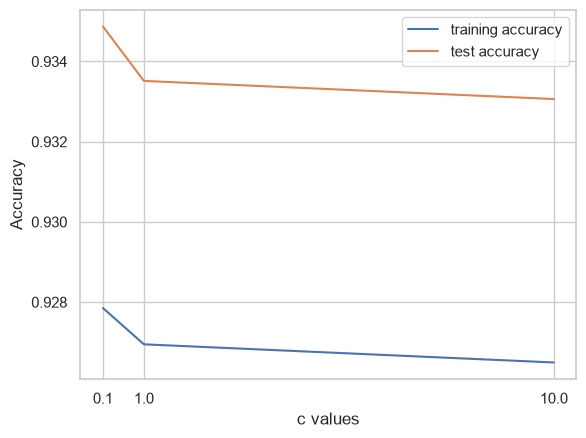

In [82]:

cmp_train_test(lrgs_train_eval , lrgs_test_eval , "c values" , c_vals)

In [83]:
# Choice of c_val configuration 

final_lrg = construct_lrg(0.1)
final_lrg_prediction = lrg_predict(final_lrg , x_test)
lrg_eval_results =  lrg_eval(final_lrg_prediction["prediction"] , y_test , 0.1 )




c_val  :  0.1



accuracy  :  0.9348710990502035



precision  :  0.9350517488752995



recall  :  0.9348710990502035



f1score  :  0.9347360046462422





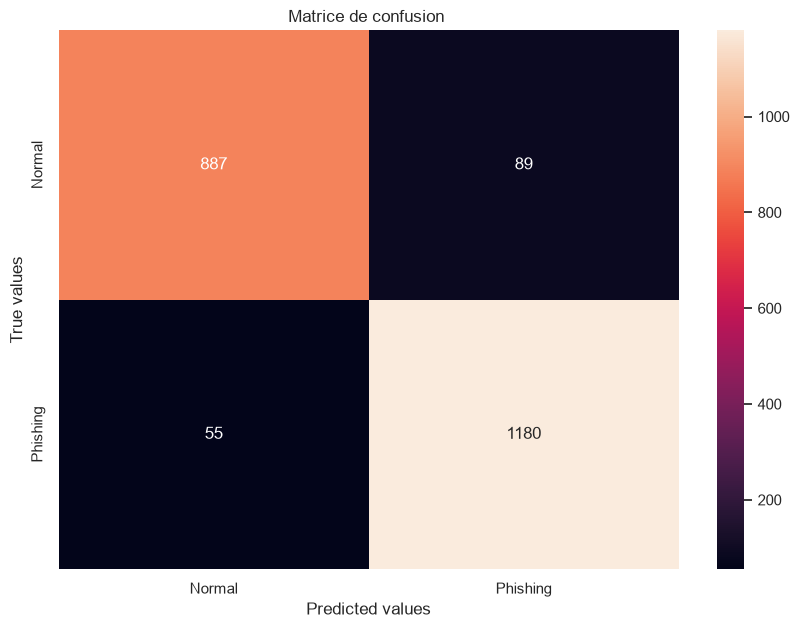

In [84]:
# METRICS 

show_metrics(lrg_eval_results)

#### **4. SVM**

In [85]:
# IMPORTATION
from sklearn.svm import SVC

In [86]:
# INITIALISATION / TRAINING

def construct_svm(c_val , x , y):
    svm = SVC(kernel="rbf" , C=c_val , gamma="scale")
    svm.fit(x , y)
    return svm 


In [87]:
# PREDICTION 

def svm_predict(svm , x_predict ):
    y_pred = svm.predict(x_predict)
    return {"c_val":svm.C , "prediction":y_pred }

In [88]:
# Testing different values of C 

c_vals_svm = [0.1 , 1 , 10]
svms_train = {}
svms_test = {}

for c_val in c_vals_svm:
    svm = construct_svm(c_val , x_train , y_train)
    svms_train[c_val] = svm_predict(svm , x_train)
    svms_test[c_val] = svm_predict(svm , x_test)

print(svms_train)
print(svms_test)

{0.1: {'c_val': 0.1, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}, 1: {'c_val': 1, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}, 10: {'c_val': 10, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}}
{0.1: {'c_val': 0.1, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}, 1: {'c_val': 1, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}, 10: {'c_val': 10, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}}


In [89]:
# EVALUATION 

def svms_eval(svms , real_y):
    results = {}

    for key , item in svms.items():
        y_pred = item["prediction"]
        results[key] = {
            "c_val" : item["c_val"],
            "accuracy": accuracy_score(real_y, y_pred),
            "precision": precision_score(real_y, y_pred, average='macro', zero_division=0),
            "recall": recall_score(real_y, y_pred, average='macro', zero_division=0),
            "f1score": f1_score(real_y, y_pred, average='macro', zero_division=0),
            "confusion_matrix": confusion_matrix(real_y, y_pred)
        }
    return results

def eval_svm(y_pred , real_y , c_val):
    # Compute evaluation metrics comparing y_pred with real_y
    results = {
        "c_val" : c_val,
        "accuracy": accuracy_score(real_y, y_pred),
        "precision": precision_score(real_y, y_pred, average='macro', zero_division=0),
        "recall": recall_score(real_y, y_pred, average='macro', zero_division=0),
        "f1score": f1_score(real_y, y_pred, average='macro', zero_division=0),
        "confusion_matrix": confusion_matrix(real_y, y_pred)
    }
    return results


In [90]:
svms_train_eval = lrgs_eval(lrgs_train , y_train)
svms_test_eval = lrgs_eval(lrgs_test , y_test)

print(svms_train_eval)
print(svms_test_eval)

{0.1: {'c_val': 0.1, 'accuracy': 0.9278525387311998, 'precision': 0.9279215201253991, 'recall': 0.9278525387311998, 'f1score': 0.9277356776610951, 'confusion_matrix': array([[3546,  375],
       [ 263, 4659]])}, 1: {'c_val': 1, 'accuracy': 0.9269478683704625, 'precision': 0.9269524913294581, 'recall': 0.9269478683704625, 'f1score': 0.9268569648008823, 'confusion_matrix': array([[3554,  367],
       [ 279, 4643]])}, 10: {'c_val': 10, 'accuracy': 0.9264955331900938, 'precision': 0.9264950389716425, 'recall': 0.9264955331900938, 'f1score': 0.9264063147392472, 'confusion_matrix': array([[3553,  368],
       [ 282, 4640]])}}
{0.1: {'c_val': 0.1, 'accuracy': 0.9348710990502035, 'precision': 0.9350517488752995, 'recall': 0.9348710990502035, 'f1score': 0.9347360046462422, 'confusion_matrix': array([[ 887,   89],
       [  55, 1180]])}, 1: {'c_val': 1, 'accuracy': 0.9335142469470827, 'precision': 0.933639375574251, 'recall': 0.9335142469470827, 'f1score': 0.9333898392567606, 'confusion_matrix':

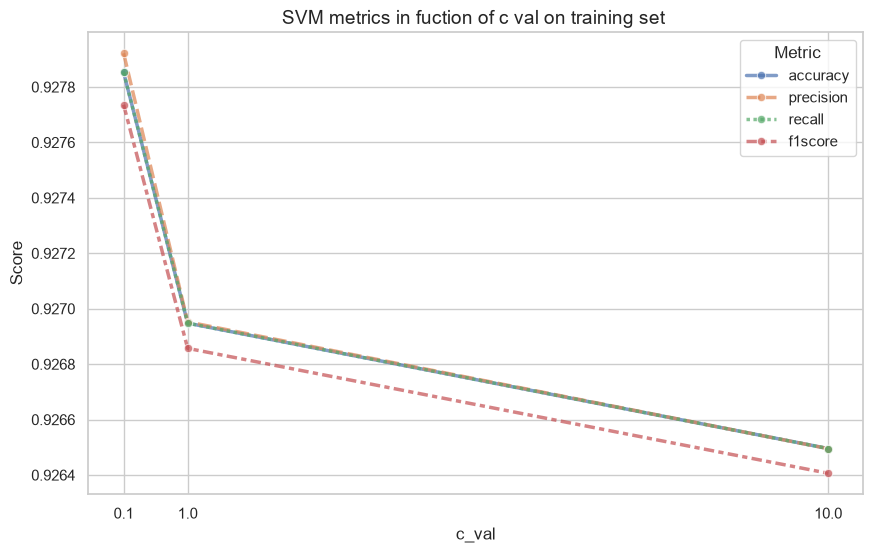

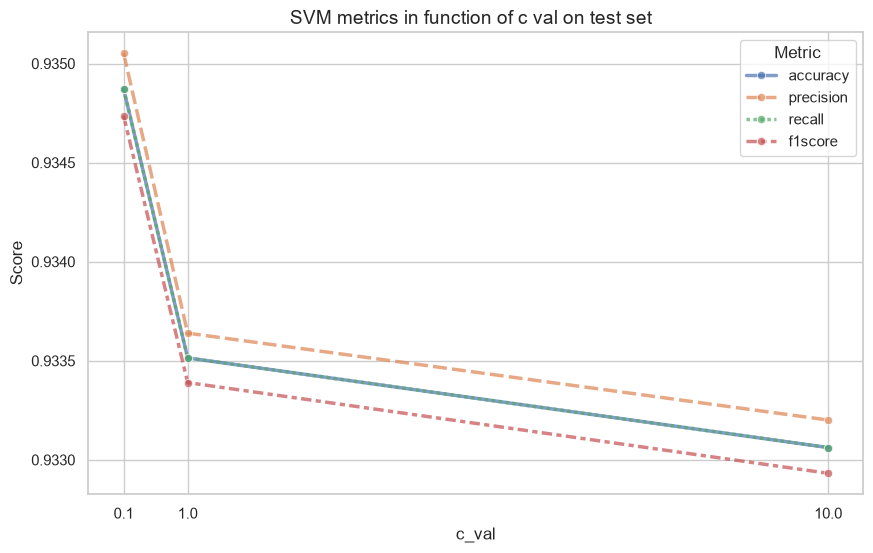

In [91]:
# TRAIN / TEST COMPAIRISIOn 
plot_cmp(svms_train_eval , "c_val" , "SVM metrics in fuction of c val on training set ")
plot_cmp(svms_test_eval , "c_val" , "SVM metrics in function of c val on test set  ")


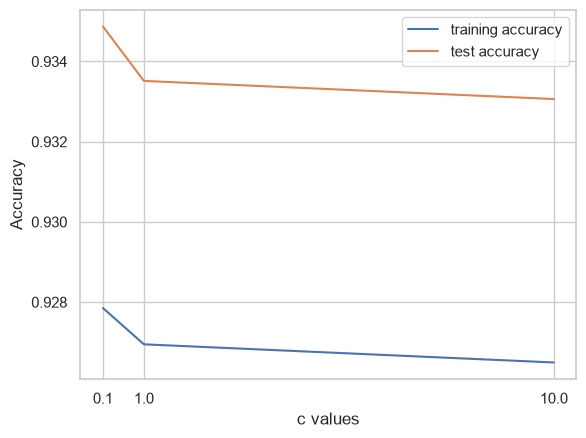

In [92]:
cmp_train_test(svms_train_eval , svms_test_eval , "c values" , c_vals_svm)

In [93]:
# Choice of configuration 

final_svm = construct_svm(0.1 , x_train , y_train)
final_svm_prediction = svm_predict(final_svm , x_test)
svm_eval_results = eval_svm(final_svm_prediction["prediction"] , y_test , 0.1)


c_val  :  0.1



accuracy  :  0.9330619629127092



precision  :  0.9341544158904724



recall  :  0.9300893508993164



f1score  :  0.9318319309244899





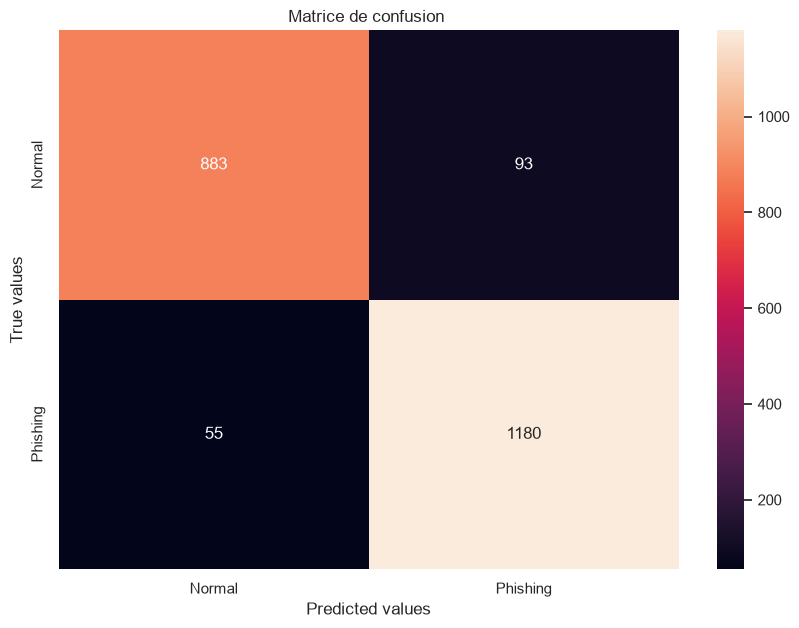

In [94]:
# METRICS

show_metrics(svm_eval_results)

#### **5. Decision tree**

In [95]:
# IMPORTATION
from sklearn.tree import DecisionTreeClassifier

In [96]:
# INITIALISATION / TRAINING

def construct_dt(depth):
    dt = DecisionTreeClassifier(max_depth=depth , random_state=42)
    dt.fit(x_train , y_train)
    return dt


In [97]:
# PREDICTION 

def dt_predict(dt , x_pred ):
    # predictions sur l'apprentissage ET sur la validation
    return {"depth":dt.max_depth , "prediction" : dt.predict(x_pred)}


In [98]:
# Trying different max depths 

depths = [5 , 10 , 15 , 20 ]

dts_train = {}
dts_test = {}

for d in depths:
    dt = construct_dt(d)
    dts_train[d] = dt_predict(dt , x_train)
    dts_test[d] = dt_predict(dt,x_test)

print(dts_train)
print(dts_test)


{5: {'depth': 5, 'prediction': array([0, 1, 1, ..., 1, 1, 0], shape=(8843,))}, 10: {'depth': 10, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}, 15: {'depth': 15, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}, 20: {'depth': 20, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}}
{5: {'depth': 5, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}, 10: {'depth': 10, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}, 15: {'depth': 15, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}, 20: {'depth': 20, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}}


In [99]:
# EVALUATION 

def eval_dts(dts , real_y):
    results = {}

    for key , item in dts.items():
        y_pred = item["prediction"]
        results[key] = {
            "depth" : item["depth"],
            "accuracy": accuracy_score(real_y, y_pred),
            "precision": precision_score(real_y, y_pred, average='macro', zero_division=0),
            "recall": recall_score(real_y, y_pred, average='macro', zero_division=0),
            "f1score": f1_score(real_y, y_pred, average='macro', zero_division=0),
            "confusion_matrix": confusion_matrix(real_y, y_pred)
        }
    return results

def eval_dt(y_pred , real_y , depth):

    # Compute evaluation metrics comparing y_pred with real_y
    results = {
        "depth" : depth,
        "accuracy": accuracy_score(real_y, y_pred),
        "precision": precision_score(real_y, y_pred, average='macro', zero_division=0),
        "recall": recall_score(real_y, y_pred, average='macro', zero_division=0),
        "f1score": f1_score(real_y, y_pred, average='macro', zero_division=0),
        "confusion_matrix": confusion_matrix(real_y, y_pred)
    }
    return results

In [100]:
dts_train_eval = eval_dts(dts_train , y_train)
dts_test_eval = eval_dts(dts_test , y_test)

print(dts_train_eval)
print(dts_test_eval)

{5: {'depth': 5, 'accuracy': 0.9215198462060387, 'precision': 0.9281283759317946, 'recall': 0.915132895407583, 'f1score': 0.9194576112915746, 'confusion_matrix': array([[3367,  554],
       [ 140, 4782]])}, 10: {'depth': 10, 'accuracy': 0.9591767499717291, 'precision': 0.9582089807654586, 'recall': 0.9592303800548438, 'f1score': 0.9586939916565389, 'confusion_matrix': array([[3763,  158],
       [ 203, 4719]])}, 15: {'depth': 15, 'accuracy': 0.9842813524821893, 'precision': 0.9841635744692674, 'recall': 0.9839865585873625, 'f1score': 0.9840744255974323, 'confusion_matrix': array([[3848,   73],
       [  66, 4856]])}, 20: {'depth': 20, 'accuracy': 0.9910663801877191, 'precision': 0.9908161044827843, 'recall': 0.9910930588592396, 'f1score': 0.9909529898055971, 'confusion_matrix': array([[3887,   34],
       [  45, 4877]])}}
{5: {'depth': 5, 'accuracy': 0.9271822704658526, 'precision': 0.9336004745631745, 'recall': 0.9208510320568128, 'f1score': 0.9252217848367255, 'confusion_matrix': arr

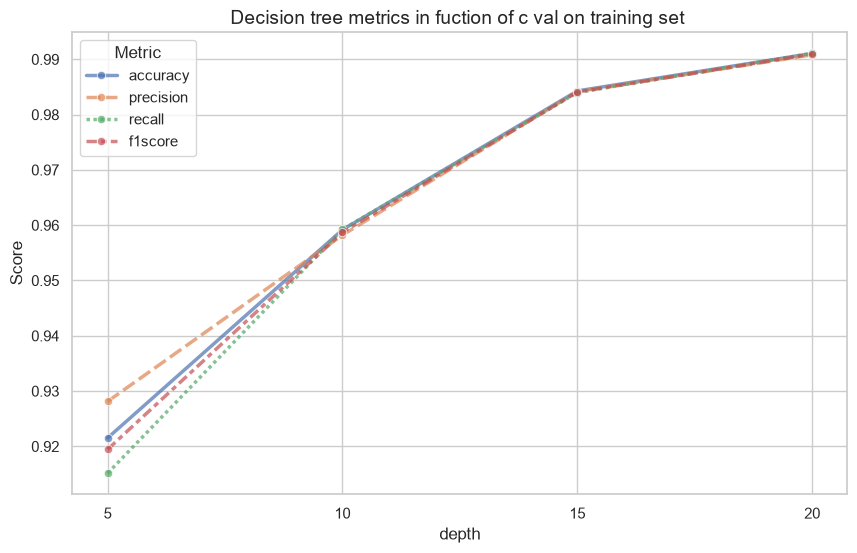

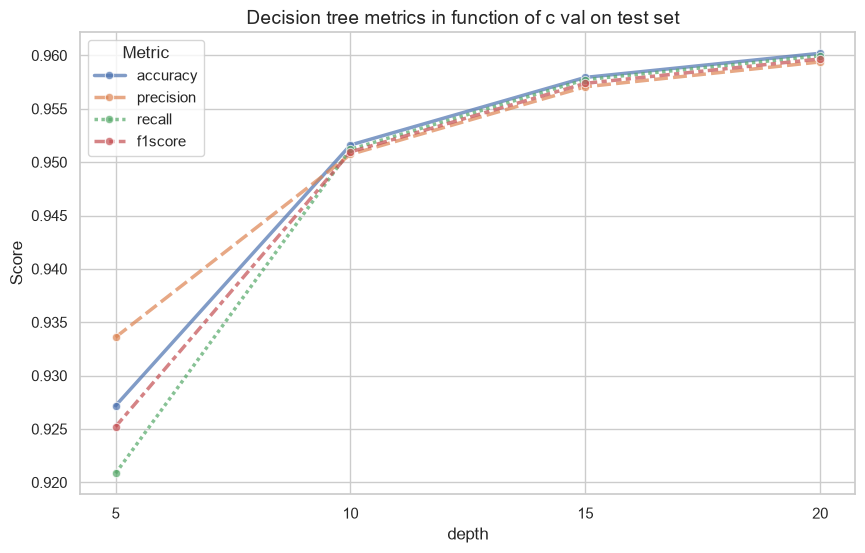

In [101]:
# TRAIN/TEST COMPAIRISION 
plot_cmp(dts_train_eval , "depth" , "Decision tree metrics in fuction of c val on training set ")
plot_cmp(dts_test_eval , "depth" , "Decision tree metrics in function of c val on test set  ")


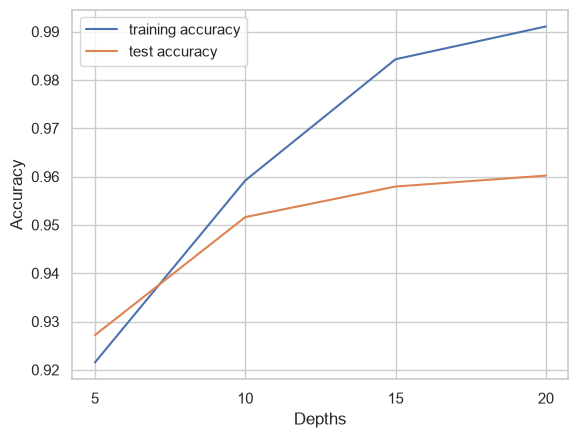

In [102]:
cmp_train_test(dts_train_eval , dts_test_eval , "Depths" , depths)

In [103]:
# Choice of depth configuration 

final_dt = construct_dt(20)
final_dt_prediction = dt_predict(final_dt , x_test)

dt_eval_results = eval_dt(final_dt_prediction["prediction"] , y_test , 20)



depth  :  20



accuracy  :  0.9601990049751243



precision  :  0.9593890186083431



recall  :  0.9599675615583726



f1score  :  0.9596709470304976





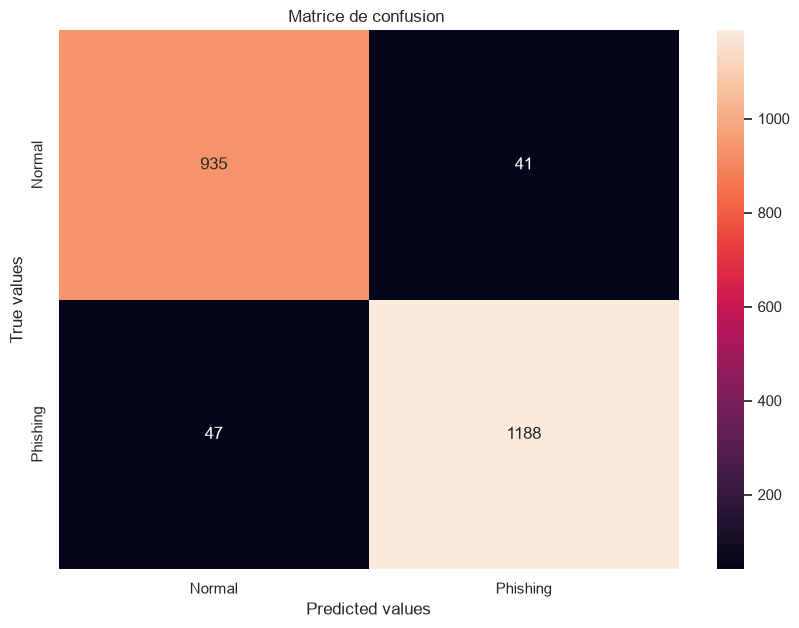

In [104]:
# METRICS 

show_metrics(dt_eval_results)


#### **6. Gradient boosting**

In [105]:
# IMPORTATION
from sklearn.ensemble import GradientBoostingClassifier



In [ ]:
# INITIALISATION / TRAINING

def construct_gbc(depth):
    gbc = GradientBoostingClassifier(max_depth= depth , learning_rate= 0.7)
    gbc.fit(x_train,y_train)
    return gbc



In [107]:
# PREDICTION 

def gbc_predict(gbc , x_pred):
    y_pred = gbc.predict(x_pred)
    return {"depth" : gbc.max_depth , "prediction" : y_pred }



In [120]:
# Trying different max depths 

depths_gbc = [5 , 10 , 15 , 20 ]

gbcs_train = {}
gbcs_test = {}

for d in depths_gbc :
    gbc = construct_gbc(d)
    gbcs_train[d] = gbc_predict(gbc , x_train)
    gbcs_test[d] = gbc_predict(gbc,x_test)

print(gbcs_train)
print(gbcs_test)

{5: {'depth': 5, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}, 10: {'depth': 10, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}, 15: {'depth': 15, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}, 20: {'depth': 20, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}}
{5: {'depth': 5, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}, 10: {'depth': 10, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}, 15: {'depth': 15, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}, 20: {'depth': 20, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}}


In [126]:
# EVALUATION 

def eval_gbcs(gbcs , real_y ):
    results = {}
    
    for key , item in gbcs.items():
        y_pred = item["prediction"]
        results[key] = {
            "depth" : item["depth"],
            "accuracy": accuracy_score(real_y, y_pred),
            "precision": precision_score(real_y, y_pred, average='macro', zero_division=0),
            "recall": recall_score(real_y, y_pred, average='macro', zero_division=0),
            "f1score": f1_score(real_y, y_pred, average='macro', zero_division=0),
            "confusion_matrix": confusion_matrix(real_y, y_pred)
        }
    return results
    

def eval_gbc(y_pred , real_y , depth):
    # Compute evaluation metrics comparing y_pred with real_y
        results = {
            "depth" : depth,
            "accuracy": accuracy_score(real_y, y_pred),
            "precision": precision_score(real_y, y_pred, average='macro', zero_division=0),
            "recall": recall_score(real_y, y_pred, average='macro', zero_division=0),
            "f1score": f1_score(real_y, y_pred, average='macro', zero_division=0),
            "confusion_matrix": confusion_matrix(real_y, y_pred)
        }
        return results
    

In [127]:
# TRAIN/TEST COMPARISION 

gbcs_train_eval = eval_gbcs(gbcs_train , y_train)
gbcs_test_eval = eval_gbcs(gbcs_test , y_test)

print(gbcs_train_eval)
print(gbcs_test_eval)

{5: {'depth': 5, 'accuracy': 0.9908402125975347, 'precision': 0.9909950357148415, 'recall': 0.9904490153510292, 'f1score': 0.9907162108487597, 'confusion_matrix': array([[3870,   51],
       [  30, 4892]])}, 10: {'depth': 10, 'accuracy': 0.9910663801877191, 'precision': 0.9910650152057494, 'recall': 0.9908337211740075, 'f1score': 0.9909483009326854, 'confusion_matrix': array([[3877,   44],
       [  35, 4887]])}, 15: {'depth': 15, 'accuracy': 0.9910663801877191, 'precision': 0.9911437621454806, 'recall': 0.9907559198684378, 'f1score': 0.9909468750210989, 'confusion_matrix': array([[3874,   47],
       [  32, 4890]])}, 20: {'depth': 20, 'accuracy': 0.989596290851521, 'precision': 0.9896932547474641, 'recall': 0.9892278483386998, 'f1score': 0.9894562861144324, 'confusion_matrix': array([[3866,   55],
       [  37, 4885]])}}
{5: {'depth': 5, 'accuracy': 0.9706015377657169, 'precision': 0.9712368696034758, 'recall': 0.9691718656666888, 'f1score': 0.9701293035450135, 'confusion_matrix': arr

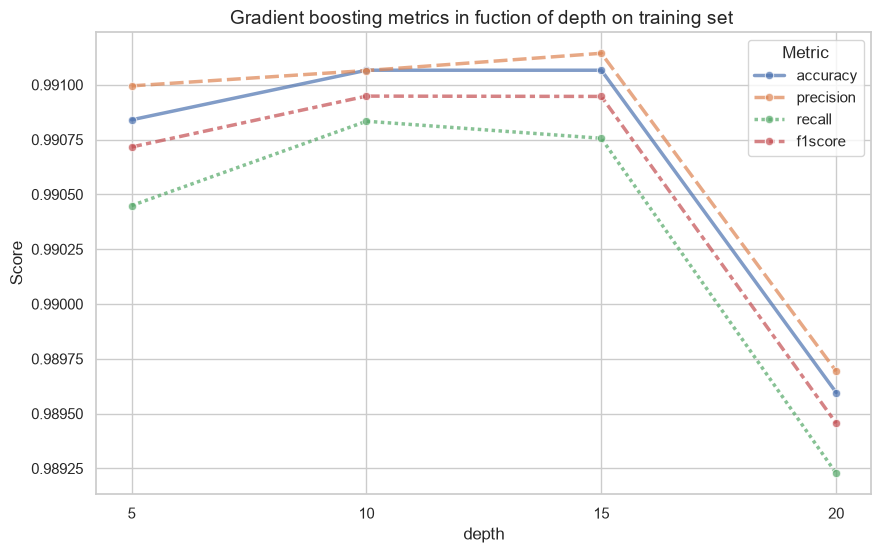

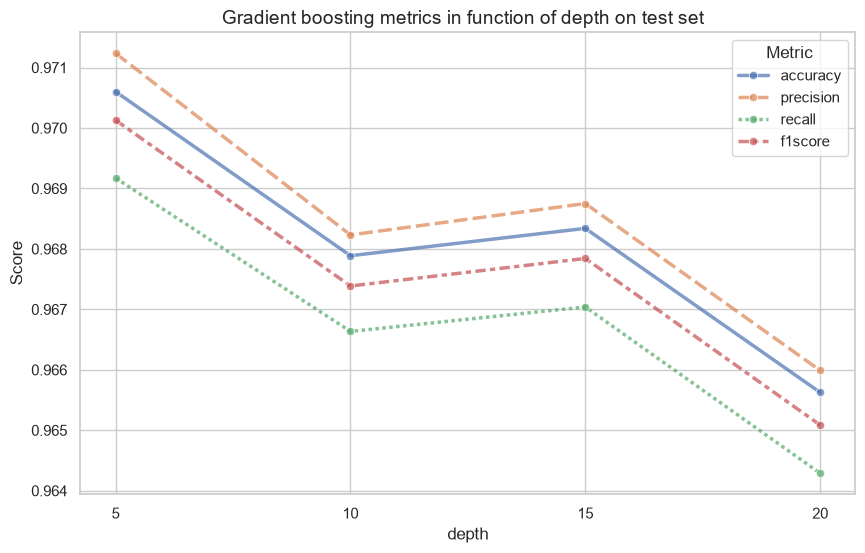

In [128]:

plot_cmp(gbcs_train_eval , "depth" , "Gradient boosting metrics in fuction of depth on training set ")
plot_cmp(gbcs_test_eval , "depth" , "Gradient boosting metrics in function of depth on test set  ")


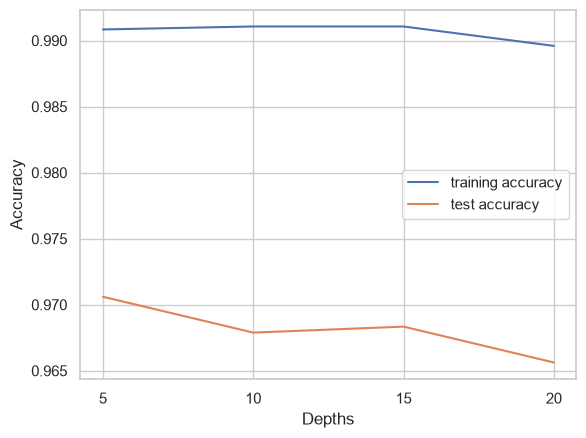

In [129]:
cmp_train_test(gbcs_train_eval , gbcs_test_eval , "Depths" , depths)

In [165]:
# Choice of configuration 

final_gbc = construct_dt(15)
final_gbc_prediction = dt_predict(final_gbc , x_test)

gbc_eval_results = eval_dt(final_gbc_prediction["prediction"] , y_test , 20)



depth  :  20



accuracy  :  0.9579375848032564



precision  :  0.9570595067283891



recall  :  0.9577283964956527



f1score  :  0.9573839843465837





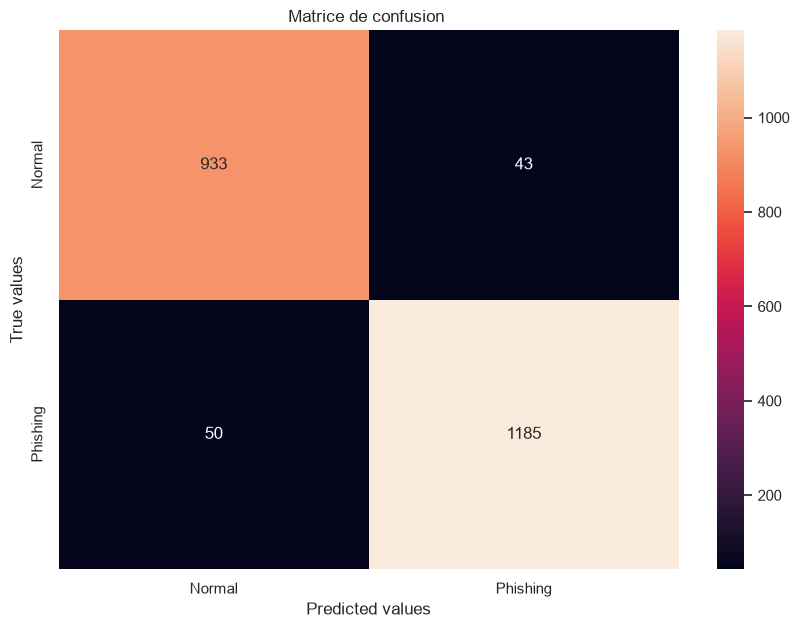

In [166]:
# METRICS 

show_metrics(gbc_eval_results)


#### **7. Xgboost**

In [167]:
# IMPORTATION
from xgboost import XGBClassifier

In [180]:
# INITIALISATION / TRAINING

def construct_xgb(lr):
    xgb = XGBClassifier(learning_rate=lr , n_estimators = 100 , random_state = 42)
    xgb.fit(x_train , y_train)
    return xgb 

    

In [181]:
# PREDICTION 

def xgb_predict(xgb , x_pred):
    return {"learning_rate" : xgb.learning_rate , "prediction" : xgb.predict(x_pred)
}
    

In [189]:
learning_rates = [0.01 , 0.05 , 0.1 , 0.2 , 0.3 , 0.5 , 0.7 , 0.9]

xgbs_train = {}
xgbs_test = {}

for lr in learning_rates : 
    xgb = construct_xgb(lr)
    xgbs_train[lr] = xgb_predict(xgb , x_train)
    xgbs_test[lr] = xgb_predict(xgb , x_test)

print(xgbs_train)
print(xgbs_test)

{0.01: {'learning_rate': 0.01, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}, 0.05: {'learning_rate': 0.05, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}, 0.1: {'learning_rate': 0.1, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}, 0.2: {'learning_rate': 0.2, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}, 0.3: {'learning_rate': 0.3, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}, 0.5: {'learning_rate': 0.5, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}, 0.7: {'learning_rate': 0.7, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}, 0.9: {'learning_rate': 0.9, 'prediction': array([0, 0, 1, ..., 1, 1, 0], shape=(8843,))}}
{0.01: {'learning_rate': 0.01, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}, 0.05: {'learning_rate': 0.05, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}, 0.1: {'learning_rate': 0.1, 'prediction': array([0, 1, 1, ..., 1, 1, 1], shape=(2211,))}, 

In [196]:
# EVALUATION 

def eval_xgbs(xgbs , real_y ):
    results = {}
    
    for key , item in xgbs.items():
        y_pred = item["prediction"]
        results[key] = {
            "learning_rate" : item["learning_rate"],
            "accuracy": accuracy_score(real_y, y_pred),
            "precision": precision_score(real_y, y_pred, average='macro', zero_division=0),
            "recall": recall_score(real_y, y_pred, average='macro', zero_division=0),
            "f1score": f1_score(real_y, y_pred, average='macro', zero_division=0),
            "confusion_matrix": confusion_matrix(real_y, y_pred)
        }
    return results
    

def eval_xgb(y_pred , real_y , lr):
    # Compute evaluation metrics comparing y_pred with real_y
        results = {
            "learning_rate" : lr,
            "accuracy": accuracy_score(real_y, y_pred),
            "precision": precision_score(real_y, y_pred, average='macro', zero_division=0),
            "recall": recall_score(real_y, y_pred, average='macro', zero_division=0),
            "f1score": f1_score(real_y, y_pred, average='macro', zero_division=0),
            "confusion_matrix": confusion_matrix(real_y, y_pred)
        }
        return results
    

In [191]:
# TRAIN/TEST COMPARISION 

xgbs_train_eval = eval_xgbs(xgbs_train , y_train)
xgbs_test_eval = eval_xgbs(xgbs_test , y_test)

print(xgbs_train_eval)
print(xgbs_test_eval)

{0.01: {'learning_rate': 0.01, 'accuracy': 0.9374646613140337, 'precision': 0.9396265428618997, 'recall': 0.933994750652904, 'f1score': 0.9362795081369848, 'confusion_matrix': array([[3542,  379],
       [ 174, 4748]])}, 0.05: {'learning_rate': 0.05, 'accuracy': 0.9600814203324664, 'precision': 0.9604585900780573, 'recall': 0.9586426343278531, 'f1score': 0.959486039260623, 'confusion_matrix': array([[3709,  212],
       [ 141, 4781]])}, 0.1: {'learning_rate': 0.1, 'accuracy': 0.9731991405631573, 'precision': 0.9732337701904328, 'recall': 0.972449295984976, 'f1score': 0.9728290871847395, 'confusion_matrix': array([[3787,  134],
       [ 103, 4819]])}, 0.2: {'learning_rate': 0.2, 'accuracy': 0.9837159335067285, 'precision': 0.983973952630669, 'recall': 0.9830377609141785, 'f1score': 0.9834888765104388, 'confusion_matrix': array([[3831,   90],
       [  54, 4868]])}, 0.3: {'learning_rate': 0.3, 'accuracy': 0.9876738663349542, 'precision': 0.9880916544745659, 'recall': 0.9869562989315288, 

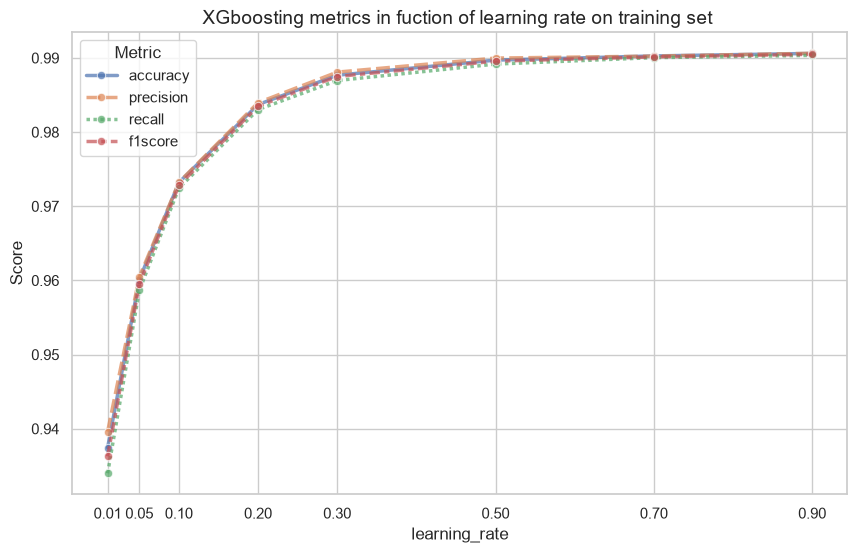

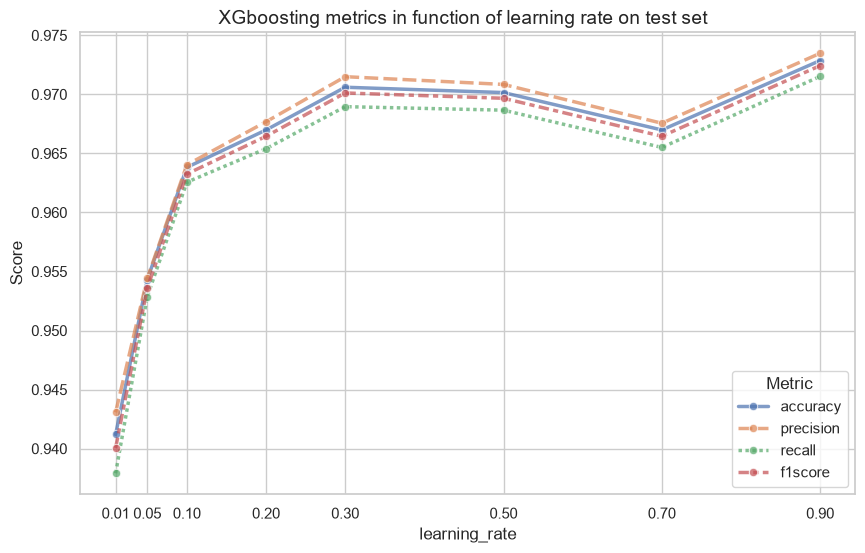

In [192]:

plot_cmp(xgbs_train_eval , "learning_rate" , "XGboosting metrics in fuction of learning rate on training set ")
plot_cmp(xgbs_test_eval , "learning_rate" , "XGboosting metrics in function of learning rate on test set  ")


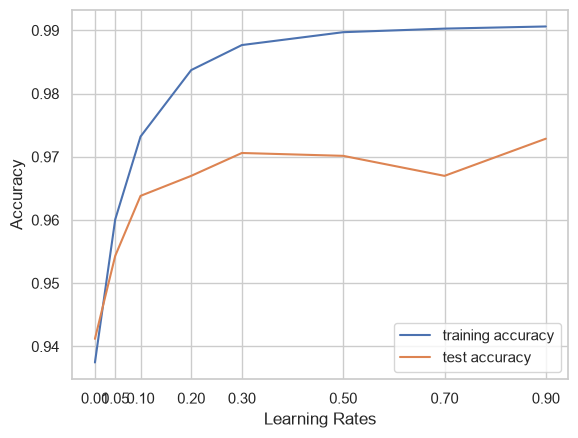

In [193]:
cmp_train_test(xgbs_train_eval , xgbs_test_eval , "Learning Rates" , learning_rates)

In [199]:
# CHoice of configuration 

final_xgb = construct_xgb(0.9)
final_xgb_prediction = xgb_predict(final_xgb , x_test)
xgb_eval_results = eval_xgb(final_xgb_prediction["prediction"] , y_test , 0.9)

print(xgb_eval_results)

{'learning_rate': 0.9, 'accuracy': 0.9728629579375848, 'precision': 0.9734770163299105, 'recall': 0.9715184675117807, 'f1score': 0.9724302297356162, 'confusion_matrix': array([[ 937,   39],
       [  21, 1214]])}


learning_rate  :  0.9



accuracy  :  0.9728629579375848



precision  :  0.9734770163299105



recall  :  0.9715184675117807



f1score  :  0.9724302297356162





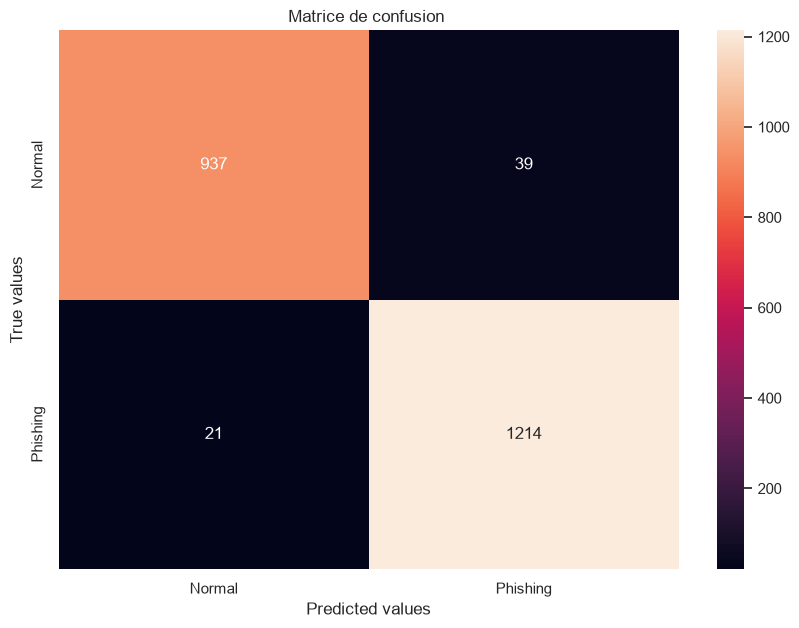

In [198]:
# METRICS 

show_metrics(xgb_eval_results)

## **Model comparision**

              Model  Accuracy  Precision   Recall  F1 Score Specific Param  Param Value
            XGBoost  0.972863   0.973477 0.971518  0.972430            NaN          NaN
  Gradient Boosting  0.970602   0.971237 0.969172  0.970129          depth          5.0
      Decision Tree  0.960199   0.959389 0.959968  0.959671          depth         20.0
K-Nearest Neighbors  0.941655   0.941662 0.941655  0.941658      neighbors          3.0
Logistic Regression  0.934871   0.935052 0.934871  0.934736          c_val          0.1
                SVM  0.933062   0.934154 0.930089  0.931832          c_val          0.1
        Naive Bayes  0.628223   0.794254 0.628223  0.591314            NaN          NaN


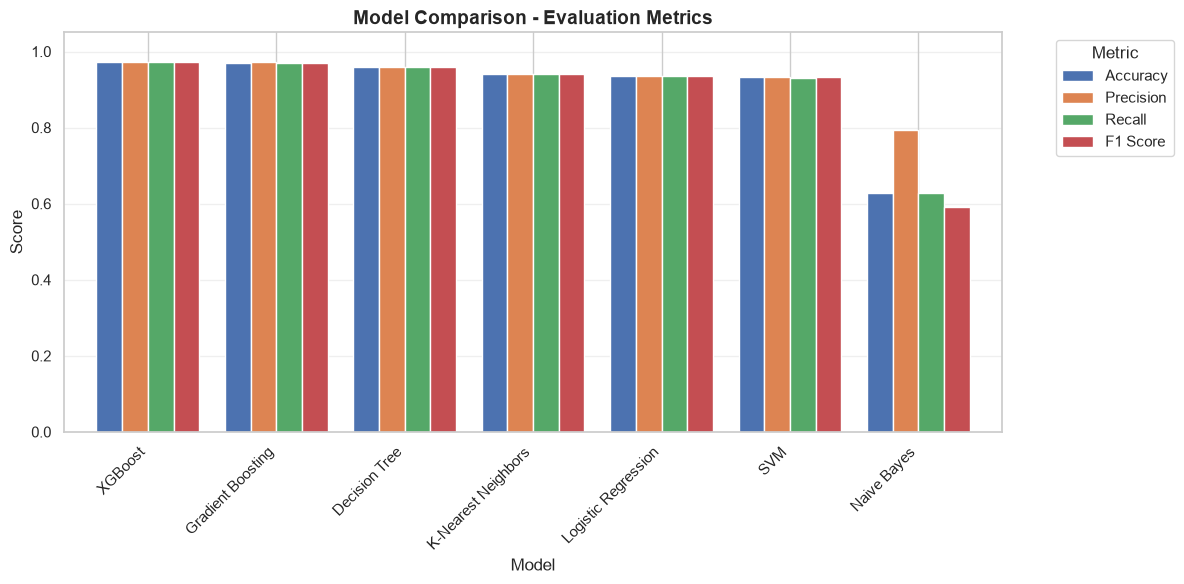

In [203]:
import os
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
# 1. Aggregate, Compare, and Plot Evaluation Metrics
all_results = []
def add(m, d, pn=None, pv=None):
    if d is None: return
    r = {'Model': m, 'Accuracy': d.get('accuracy'), 'Precision': d.get('precision'), 'Recall': d.get('recall'), 'F1 Score': d.get('f1score')}
    if pn is not None and pv is not None: r['Specific Param'] = pn; r['Param Value'] = pv
    all_results.append(r)
if 'knn_eval_results' in globals():
    add('K-Nearest Neighbors', knn_eval_results, 'neighbors', knn_eval_results.get('neighbors'))
if 'nb_eval_results' in globals():
    add('Naive Bayes', nb_eval_results)
if 'lrg_eval_results' in globals():
    add('Logistic Regression', lrg_eval_results, 'c_val', lrg_eval_results.get('c_val'))
if 'svm_eval_results' in globals():
    add('SVM', svm_eval_results, 'c_val', svm_eval_results.get('c_val'))
if 'dt_eval_results' in globals():
    add('Decision Tree', dt_eval_results, 'depth', dt_eval_results.get('depth'))
if 'gbcs_test_eval' in globals():
    best_depth = max(gbcs_test_eval.keys(), key=lambda k: gbcs_test_eval[k].get('f1score', 0))
    add('Gradient Boosting', gbcs_test_eval[best_depth], 'depth', best_depth)
# XGBoost (if present)
if 'xgb_eval_results' in globals():
    add('XGBoost', xgb_eval_results)
if 'xgbc_eval_results' in globals():
    add('XGBoost', xgbc_eval_results)
comparison_df = pd.DataFrame(all_results)
if not comparison_df.empty:
    comparison_df = comparison_df.sort_values('F1 Score', ascending=False).reset_index(drop=True)
    display_cols = ['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score']
    if 'Specific Param' in comparison_df.columns:
        display_cols += ['Specific Param', 'Param Value']
    print(comparison_df[display_cols].to_string(index=False))
    metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
    plot_df = comparison_df.set_index('Model')[metrics]
    fig, ax = plt.subplots(figsize=(12, 6))
    plot_df.plot(kind='bar', ax=ax, width=0.8)
    ax.set_title('Model Comparison - Evaluation Metrics', fontsize=14, fontweight='bold')
    ax.set_xlabel('Model', fontsize=12)
    ax.set_ylabel('Score', fontsize=12)
    ax.set_ylim(0, 1.05)
    ax.legend(title='Metric', bbox_to_anchor=(1.05, 1), loc='upper left')
    ax.grid(True, axis='y', alpha=0.3)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
else:
    print('No evaluation results found to compare.')


In [209]:
# 2. Best Model Selection & Retraining

if not comparison_df.empty:

    best_row = comparison_df.iloc[0]

    best_model_name = best_row['Model']

    best_f1 = best_row['F1 Score']

    print('Best model: {} (F1 Score: {:.4f})'.format(best_model_name, best_f1))

else:

    best_model = None

    print('No comparison data available; skipping model selection.')



Best model: XGBoost (F1 Score: 0.9724)


#### **Storing best model**

In [216]:

# instantiate the model
xgb = XGBClassifier(max_depth=4,learning_rate=0.9)

# fit the model 
xgb.fit(x_train,y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [218]:
# dump information to that file

pickle.dump(xgb, open('pickle/model.pkl', 'wb'))